# SpamJam: data exploration

SpamJam helps GrandPied's IT team flag spam (`is_spam` = 1) while protecting legitimate emails (`is_spam` = 0). The problem and the cost of each mistake are described in the README and used in `analysis.ipynb` to choose our metric and threshold.

We load the Spambase dataset (UCI, id 94) through our package. The first run downloads it and saves it, and then later runs read that file. We then remove duplicates, split the data into a training and a test set, and explore the training set only.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from spamjam.config import load_config
from spamjam.constants import PROJECT_ROOT, TARGET_COL
from spamjam.data import DatasetLoader

config = load_config()

# Charts are also saved as PNG files in results/, for the report and the slides.
results_dir = PROJECT_ROOT / config["output"]["results_dir"]
results_dir.mkdir(parents=True, exist_ok=True)


def save_and_show(filename: str) -> None:
    """Save the current chart to results/ as a PNG file, then show it."""
    plt.savefig(results_dir / f"{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [2]:
logging.basicConfig(level=logging.INFO)
pd.set_option("display.max_columns", None)

#loading
loader = DatasetLoader.from_config()
df = loader.load_data()

df.shape

INFO:spamjam.data:Reading /Users/alajemba/spamjam/data/raw/spambase.csv


(4601, 58)

## Duplicates

In [3]:
df_clean = loader.remove_duplicates(df)

INFO:spamjam.data:Removed 391 duplicate rows


## Train / test split

In [4]:
train_df, test_df = loader.split(df_clean)
loader.save_split(train_df, test_df)

print("SPLIT VERIFICATION")
print(f"Train: {train_df.shape}, spam {train_df['is_spam'].mean():.2%}")
print(f"Test:  {test_df.shape}, spam {test_df['is_spam'].mean():.2%}")

INFO:spamjam.data:Saved /Users/alajemba/spamjam/data/processed/train.csv and /Users/alajemba/spamjam/data/processed/test.csv


SPLIT VERIFICATION
Train: (3368, 58), spam 39.88%
Test:  (842, 58), spam 39.90%


We split once, stratified, and save both sets. From here on we only use the training set; the test set is used once, at the end.

## Columns and types

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3368 entries, 436 to 3242
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              3368 non-null   float64
 1   word_freq_address           3368 non-null   float64
 2   word_freq_all               3368 non-null   float64
 3   word_freq_3d                3368 non-null   float64
 4   word_freq_our               3368 non-null   float64
 5   word_freq_over              3368 non-null   float64
 6   word_freq_remove            3368 non-null   float64
 7   word_freq_internet          3368 non-null   float64
 8   word_freq_order             3368 non-null   float64
 9   word_freq_mail              3368 non-null   float64
 10  word_freq_receive           3368 non-null   float64
 11  word_freq_will              3368 non-null   float64
 12  word_freq_people            3368 non-null   float64
 13  word_freq_report            3368 non

In [6]:
train_df[TARGET_COL].value_counts().sort_index()

is_spam
0    2025
1    1343
Name: count, dtype: int64

All 57 features are numeric (word and character frequencies, and capital-letter run lengths), and the target `is_spam` is 0 (ham) or 1 (spam). What each column measures is described in the data dictionary, `docs/data_dictionary.md`.

## Missing values

In [7]:
train_df.isna().sum().sum()

np.int64(0)

There are no missing values, so no imputation is needed.

## Value ranges and special codes

In [8]:
train_df.describe()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
count,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.00000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000
mean,0.100383,0.117307,0.295632,0.043999,0.328002,0.096274,0.114017,0.105638,0.093337,0.253171,0.055324,0.553183,0.098355,0.062613,0.047726,0.25747,0.148774,0.189498,1.717542,0.080214,0.801781,0.143729,0.100698,0.089403,0.564602,0.280404,0.379596,0.129902,0.095992,0.101666,0.066235,0.046018,0.103979,0.047093,0.107640,0.098946,0.145270,0.016384,0.089385,0.060698,0.038406,0.138714,0.052313,0.080980,0.313916,0.178109,0.005338,0.032717,0.040720,0.146209,0.017479,0.285949,0.077270,0.046897,5.194729,52.078088,288.178444,0.398753
std,0.294424,0.485718,0.527413,1.132665,0.704859,0.284575,0.384393,0.410446,0.290937,0.690361,0.181465,0.848085,0.320621,0.368328,0.255024,0.78754,0.454326,0.555320,1.767574,0.415134,1.137508,1.138226,0.355879,0.441824,1.630888,0.912027,1.837381,0.541533,0.575262,0.421975,0.402012,0.308639,0.529811,0.309930,0.543801,0.377232,0.431231,0.255651,0.474324,0.319597,0.286796,0.770725,0.245015,0.547433,1.010119,0.874063,0.075136,0.266608,0.250978,0.289317,0.108179,0.857139,0.250516,0.452181,29.886375,211.727626,631.485389,0.489714
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.611000,7.000000,39.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.165000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.370000,0.000000,0.290000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000

No value is negative, and there are no strange codes like -1 or 999. A 0 simply means the word or character isn't in the email, so it's a real value, not missing data. Most emails have 0 for most words.

The features have very different sizes. Word and character frequencies are small numbers (usually between 0 and a few percent), while the capital-letter features are much bigger (for example, an email has about 288 capital letters on average). Some models would treat the big numbers as more important just because they're bigger, so we will scale all features to the same range in the pipeline.

### Skewed capital-letter counts

In [9]:
capital_cols = [c for c in train_df.columns if c.startswith("capital_run_length_")]
train_df[capital_cols].agg(["median", "mean", "max", "skew"]).T.round(2)

,median,mean,max,skew
capital_run_length_average,2.29,5.19,1021.5,21.87
capital_run_length_longest,15.00,52.08,9989.0,32.09
capital_run_length_total,100.00,288.18,15841.0,9.65


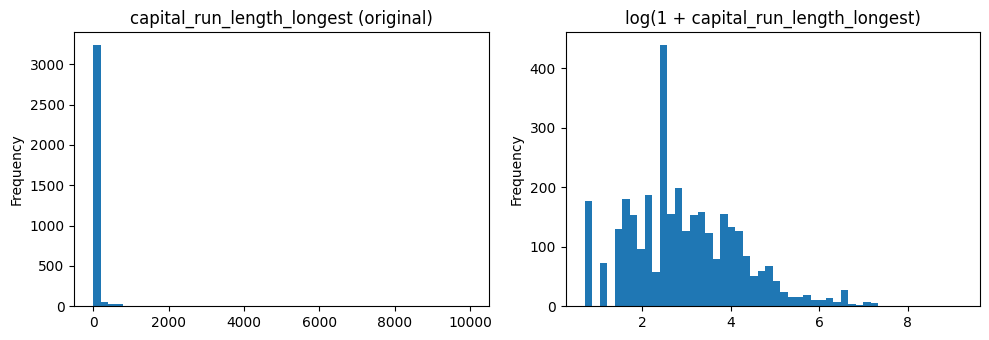

In [10]:
col = "capital_run_length_longest"
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df[col].plot.hist(bins=50, ax=axes[0], title=f"{col} (original)")
np.log1p(train_df[col]).plot.hist(bins=50, ax=axes[1], title=f"log(1 + {col})")
plt.tight_layout()
save_and_show("02_capital_run_length_transform")

The three capital-letter features are strongly **right-skewed**: most emails have small values, and a few have extreme ones. Three signs show it:
- **The mean is far above the median.** For `capital_run_length_longest`, half the emails have a longest run of 15 capitals or fewer, but the mean is about 52, pulled up by a few very large values.
- **The maximum is huge compared with the middle.** One email has a run of 9,989 capitals, while 99% of emails are at or below 669. It is a single real email, not an error or a capped value, so we keep it.
- **The skewness is very high** (about 10 to 32; 0 means symmetric, above 1 is already strongly skewed).

On the histogram, almost all emails are squeezed into the first bar. After `log(1 + x)`, the values are spread much more evenly, and the skewness drops to about 0.1 to 3.

**What we do with it:** in the pipeline, we apply `log(1 + x)` to these three features before scaling, so a few extreme emails don't dominate. We check in `analysis.ipynb` with cross-validation that this actually improves the model.

## First rows

In [11]:
train_df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
436,0.0,0.0,0.00,0.0,0.00,0.05,0.00,0.34,0.0,0.00,0.11,0.81,0.05,0.11,0.0,0.00,0.75,0.0,0.00,0.0,0.00,0.0,0.05,0.00,1.16,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,0.00,0.00,0.23,0.05,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.283,0.107,0.000,0.000,0.053,0.0,1.864,32,910,1
1032,0.0,0.0,0.48,0.0,0.96,0.00,0.48,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.48,0.96,0.0,1.92,0.0,1.44,0.0,0.48,0.48,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.0,1.44,0.0,0.0,0.0,0.000,0.073,0.000,0.515,0.957,0.0,6.833,78,328,1
1803,0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,1.38,0.00,0.00,0.0,0.00,0.00,0.0,1.38,0.0,1.38,0.0,0.00,0.00,1.38,1.38,2.77,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.38,0.0,1.38,0.00,0.0,0.0,1.38,0.0,0.00,0.0,0.0,0.0,0.000,0.000,0.224,0.448,0.000,0.0,1.451,12,45,0
3504,0.0,0.0,0.00,0.0,0.88,0.00,0.00,0.00,0.0,2.65,0.88,0.00,0.00,0.00,0.0,0.00,0.00,0.0,1.76,0.0,0.00,0.0,0.00,0.00,1.76,0.88,1.76,0.88,0.88,0.88,0.88,0.88,0.00,0.88,0.88,0.88,0.88,0.0,0.88,0.88,0.0,0.0,0.88,0.0,2.65,0.0,0.0,0.0,0.142,0.855,0.000,0.285,0.000,0.0,1.777,12,80,0
2056,0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.72,0.00,0.00,0.0,0.00,0.00,0.0,1.45,0.0,2.18,0.0,0.00,0.00,1.45,0.72,1.45,0.72,0.72,0.72,0.72,0.72,0.00,0.72,0.72,0.72,0.72,0.0,0.72,0.72,0.0,0.0,0.72,0.0,0.72,0.0,0.0,0.0,0.000,0.367,0.000,0.000,0.000,0.0,1.897,12,74,0


## Leakage

All features come from the email's text, so we know them as soon as the email arrives, before anyone decides if it's spam. No feature gives away the answer, so we don't need to remove any.

One limit: the dataset has no dates, so we can't tell when each email was sent and can't check for time-based leakage. Our split is random, so the test set is not "future" emails compared to the training set. In real use, the model would always predict on newer emails than it was trained on, and spam changes over time (new words, new tricks). The data is also from around 1999 (UCI). So our test score may be more optimistic than how the model would perform on GrandPied's emails today.

## Where the data comes from

The UCI documentation explains that the legitimate emails (ham) come from the donor's own work and personal emails (George, at HP Labs, around 1999). So some words describe **him**, not spam: his name, his company (`hp`, `hpl`, `labs`), and parts of his phone numbers (`650`, `415`, `857`). We check how often these words appear in ham and in spam:

In [12]:
donor_cols = config["features"]["donor_columns"]

presence = (train_df[donor_cols] > 0).groupby(train_df[TARGET_COL]).mean().T * 100
presence.columns = ["% of ham", "% of spam"]
presence.round(1)

,% of ham,% of spam
word_freq_george,26.3,0.4
word_freq_hp,40.0,2.8
word_freq_hpl,30.2,1.5
word_freq_650,16.7,1.9
word_freq_857,7.7,0.1
word_freq_415,7.8,0.7
word_freq_labs,17.5,1.0
word_freq_telnet,11.2,0.1
word_freq_technology,18.4,6.1


These words appear in many legitimate emails and almost never in spam (for example, `hp` is in about 40% of ham and 3% of spam). They are very useful **on this dataset**, but only because they identify the donor's emails: they would mean nothing for GrandPied. Several are also strongly correlated with each other, as the next cell shows.

We test in `analysis.ipynb` what happens if we drop them, and we report this dependence on one person's emails as a limitation of our model.

In [13]:
# All pairs of features with a correlation above 0.6 (each pair listed once)
corr = train_df.drop(columns=TARGET_COL).corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs > 0.6].sort_values(ascending=False).round(3)

word_freq_857         word_freq_415           0.994
                      word_freq_direct        0.837
word_freq_415         word_freq_direct        0.833
word_freq_857         word_freq_technology    0.699
word_freq_415         word_freq_technology    0.695
word_freq_telnet      word_freq_857           0.666
word_freq_technology  word_freq_direct        0.664
word_freq_labs        word_freq_technology    0.662
word_freq_telnet      word_freq_415           0.662
                      word_freq_technology    0.656
word_freq_labs        word_freq_857           0.647
                      word_freq_415           0.643
word_freq_telnet      word_freq_direct        0.643
word_freq_labs        word_freq_direct        0.608
                      word_freq_telnet        0.601
dtype: float64

Only one group of features is strongly correlated, and it is the donor's: `857` and `415` are almost identical (about 0.99), and both are also correlated with `direct`, `technology`, `telnet` and `labs`. No other pair goes above 0.6, so there is no wider collinearity problem. Regularisation in our models (L1/L2) handles this group; the L1 model indeed sets `857` and `415` to zero.

## Target distribution

Proportion of spam: 39.88%


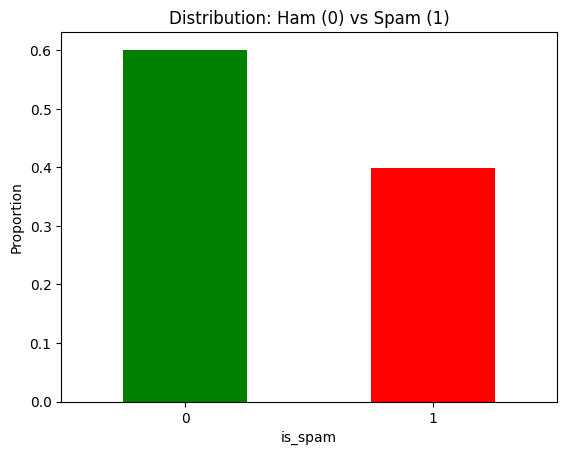

In [14]:
y = train_df[TARGET_COL]
print(f"Proportion of spam: {y.mean():.2%}")

y.value_counts(normalize=True).sort_index().plot(kind="bar", color=["green", "red"])
plt.title("Distribution: Ham (0) vs Spam (1)")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
save_and_show("01_ham_spam_distribution")

About 40% of emails are spam. The classes do not have the same amount of data so we have to ensure that when separating the data into the train and test sets we use stratify to ensure that the same proportion of the different classes exist in both the train and test sets.